# CatBoost
**Cosa cambia rispetto ai modelli precedenti.**
- le variabili **categoriche si passano così come sono** (testo): CatBoost le gestisce da solo, niente `get_dummies`;
- come per l'albero, **non serve standardizzare** le numeriche.

### Librerie e dati

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import product

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
import sklearn.metrics as skl_metr
from catboost import CatBoostClassifier

pd.set_option("display.float_format", lambda x: "%.3f" % x)

FILE_CSV = "/Users/ale/Desktop/CRIF SETTIMANA 3/Student_Depression_Dataset.csv"
RANDOM_STATE = 42

df = pd.read_csv(FILE_CSV)
df["y"] = df["Depression"].map({"No": 0, "Yes": 1})   # target 0/1
print(df.shape, df["y"].mean())

(4464, 14) 0.26904121863799285


### Variabili
Le stesse della logistica. Le binarie diventano 0/1, le categoriche restano **testo** e le elenchiamo in `COL_CAT`: CatBoost le trasforma da solo.

In [5]:
COL_CAT = ["Relationship_status", "Family_background", "Home_division", "Living_style"]
COL_NUM = ["CGPA", "Cost_without_study", "Age", "Current_semester"]

df["male"] = (df["Gender"] == "Male").astype(int)
df["no_friends"] = (df["friend_circle"] == "No").astype(int)

X = df[["male", "no_friends"] + COL_CAT + COL_NUM]
y = df["y"]
print(X.shape)

(4464, 10)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print(X_train.shape, X_test.shape, y_train.mean(), y_test.mean())

(3571, 10) (893, 10) 0.26911229347521703 0.2687569988801792


---
grid search

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def nuovo_modello(depth, lr, l2, iterations = 300):
    return CatBoostClassifier(iterations= iterations, depth=depth, learning_rate=lr, l2_leaf_reg = l2,
                              cat_features=tuple(COL_CAT),
                              auto_class_weights="Balanced", random_seed=RANDOM_STATE, verbose=0, allow_writing_files=False)

#lasciamo learning rate fisso
#proviamo 3 profondità e 2 valori di l2
righe = []
for depth, l2 in product([3, 4, 6], [3, 10, 50]):
    mod = nuovo_modello(depth, 0.03, l2)
    scores = cross_val_score(mod, X_train, y_train, cv = cv, scoring = "roc_auc")
    mod.fit(X_train, y_train)
    auc_train = skl_metr.roc_auc_score(y_train, mod.predict_proba(X_train)[:,1])
    righe.append([depth, l2, scores.mean(), scores.std(), auc_train, auc_train - scores.mean()]) 

df_grid = pd.DataFrame(righe, columns=["depth", "l2_leaf_reg", "AUC cv", "std cv", "AUC train", "scarto train-cv"])  # <-- 5
df_grid = df_grid.sort_values("AUC cv", ascending=False).reset_index(drop=True)
df_grid

,depth,l2_leaf_reg,AUC cv,std cv,AUC train,scarto train-cv
0,6,10,0.747,0.013,0.813,0.066
1,6,3,0.746,0.012,0.817,0.071
2,6,50,0.744,0.013,0.800,0.057
3,4,3,0.740,0.015,0.782,0.042
4,4,10,0.740,0.016,0.780,0.041
5,3,50,0.738,0.017,0.765,0.027
6,4,50,0.738,0.017,0.778,0.040
7,3,10,0.737,0.017,0.765,0.028
8,3,3,0.736,0.017,0.767,0.030


#anche qua creiamo metodo per scegliere la migliore.
#qua però più oscura la scelta, devo rivederla meglio (chiedi ad alessandro)

In [9]:
best = df_grid[(df_grid['depth']== 4) & (df_grid['l2_leaf_reg'] == 10)].iloc[0]
print(best)

model = nuovo_modello(int(best["depth"]), 0.03, int(best['l2_leaf_reg']))
model.fit(X_train, y_train)

depth              4.000
l2_leaf_reg       10.000
AUC cv             0.740
std cv             0.016
AUC train          0.780
scarto train-cv    0.041
Name: 4, dtype: float64


CatBoostClassifier(allow_writing_files=False, auto_class_weights='Balanced', cat_features=('Relationship_status', 'Family_background', 'Home_division', 'Living_style'), depth=4, iterations=300, l2_leaf_reg=10, learning_rate=0.03, random_seed=42, verbose=0)

**Importanza delle variabili**: quanto ogni variabile contribuisce alle previsioni (somma 100). Con CatBoost è riferita alla variabile intera (`Relationship_status`, non alle singole dummy).

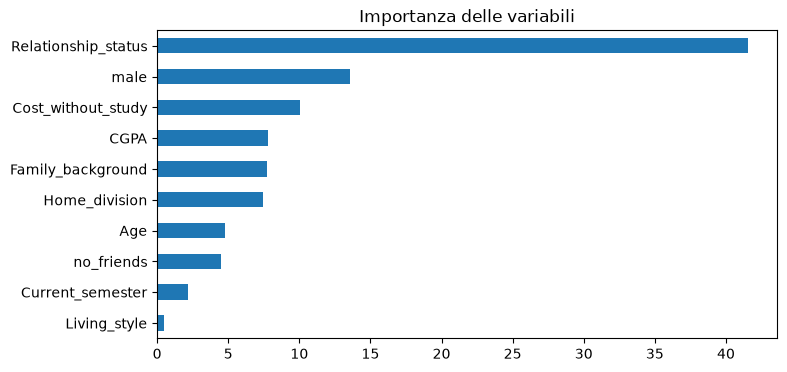

In [24]:
imp = pd.Series(model.get_feature_importance(), index=X_train.columns).sort_values()
imp.plot(kind="barh", figsize=(8, 4), title="Importanza delle variabili")
plt.show()

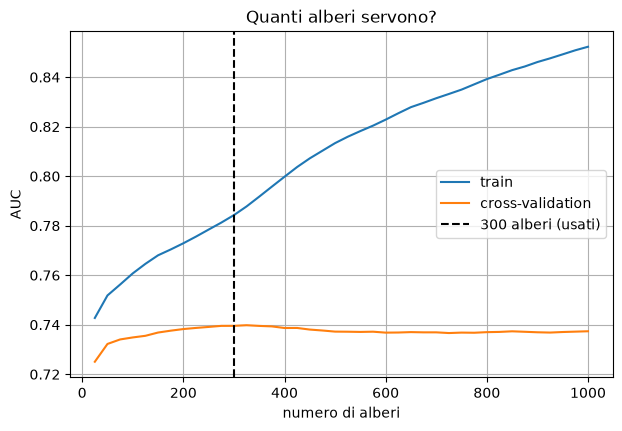

alberi      325.000
AUC cv        0.740
AUC train     0.788
Name: 12, dtype: float64

In [10]:
N_MAX = 1000
passi = list(range(25, N_MAX + 1, 25))

auc_val, auc_tr = [], []

for idx_tr, idx_va in cv.split(X_train, y_train):
    m = nuovo_modello(int(best['depth']), 0.03, int(best['l2_leaf_reg']), iterations = N_MAX)
    m.fit(X_train.iloc[idx_tr], y_train.iloc[idx_tr])
    auc_val.append([skl_metr.roc_auc_score(y_train.iloc[idx_va], m.predict_proba(X_train.iloc[idx_va], ntree_end=k)[:, 1]) for k in passi])
    auc_tr.append([skl_metr.roc_auc_score(y_train.iloc[idx_tr], m.predict_proba(X_train.iloc[idx_tr], ntree_end=k)[:, 1]) for k in passi])


curva = pd.DataFrame({"alberi": passi, "AUC cv": np.mean(auc_val, axis=0), "AUC train": np.mean(auc_tr, axis=0)})

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(curva["alberi"], curva["AUC train"], label="train")
ax.plot(curva["alberi"], curva["AUC cv"], label="cross-validation")
ax.axvline(300, color="k", ls="--", label="300 alberi (usati)")
ax.set_xlabel("numero di alberi")
ax.set_ylabel("AUC")
ax.set_title("Quanti alberi servono?")
ax.legend()
ax.grid()
plt.show()

curva.loc[curva["AUC cv"].idxmax()]

--- 
scelta soglia

In [11]:
p_cv = cross_val_predict(nuovo_modello(int(best["depth"]), 0.03, best["l2_leaf_reg"]),
                         X_train, y_train, cv=cv, method="predict_proba")[:, 1]

righe = []
for t in np.arange(0.05, 0.96, 0.05):
    pred = (p_cv >= t).astype(int)          # 1 se la probabilita' e' almeno t
    righe.append([t, skl_metr.recall_score(y_train, pred), skl_metr.precision_score(y_train, pred),
                  skl_metr.f1_score(y_train, pred), pred.mean()])

tab_soglie = pd.DataFrame(righe, columns=["soglia", "recall", "precision", "f-score", "% segnalati"])
tab_soglie

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,soglia,recall,precision,f-score,% segnalati
0,0.050,1.000,0.271,0.426,0.994
1,0.100,0.998,0.293,0.453,0.916
2,0.150,0.993,0.311,0.474,0.858
3,0.200,0.984,0.323,0.486,0.820
4,0.250,0.960,0.331,0.492,0.781
5,0.300,0.941,0.343,0.503,0.738
6,0.350,0.905,0.353,0.508,0.689
7,0.400,0.865,0.364,0.512,0.640
8,0.450,0.819,0.380,0.519,0.580
9,0.500,0.747,0.412,0.531,0.488


In [12]:
SOGLIA = tab_soglie.loc[tab_soglie["f-score"].idxmax(), "soglia"]   # soglia con f-score massimo
print("Soglia usata:", SOGLIA)

Soglia usata: 0.5


### Valutazione sul test
Stesse metriche della logistica e dell'albero. Ricorda il benchmark: rispondere sempre "No" dà circa il 73% di accuracy, quindi l'accuracy da sola non dice nulla. Guarda f-score, recall e precision.

In [13]:
prob_train = model.predict_proba(X_train)[:, 1]
prob_test = model.predict_proba(X_test)[:, 1]
pred_train = (prob_train >= SOGLIA).astype(int)
pred_test = (prob_test >= SOGLIA).astype(int)


# matrice di confusione: classe vera in riga, classe predetta in colonna
print(pd.crosstab(y_test, pred_test, rownames=["vero"], colnames=["predetto"]))

metriche = {
    "accuracy": skl_metr.accuracy_score,
    "precision": skl_metr.precision_score,
    "recall": skl_metr.recall_score,
    "f-score": skl_metr.f1_score,
    "phi-score": skl_metr.matthews_corrcoef,
}
df_metriche = pd.DataFrame({
    "train": {k: f(y_train, pred_train) for k, f in metriche.items()},
    "test": {k: f(y_test, pred_test) for k, f in metriche.items()},
})
df_metriche.loc["AUC"] = [skl_metr.roc_auc_score(y_train, model.predict_proba(X_train)[:, 1]),
                          skl_metr.roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])]
print(df_metriche)
print("Accuracy 'rispondo sempre No':", round(1 - y_test.mean(), 3))

predetto    0    1
vero              
0         376  277
1          73  167
           train  test
accuracy   0.658 0.608
precision  0.426 0.376
recall     0.786 0.696
f-score    0.553 0.488
phi-score  0.351 0.241
AUC        0.780 0.700
Accuracy 'rispondo sempre No': 0.731


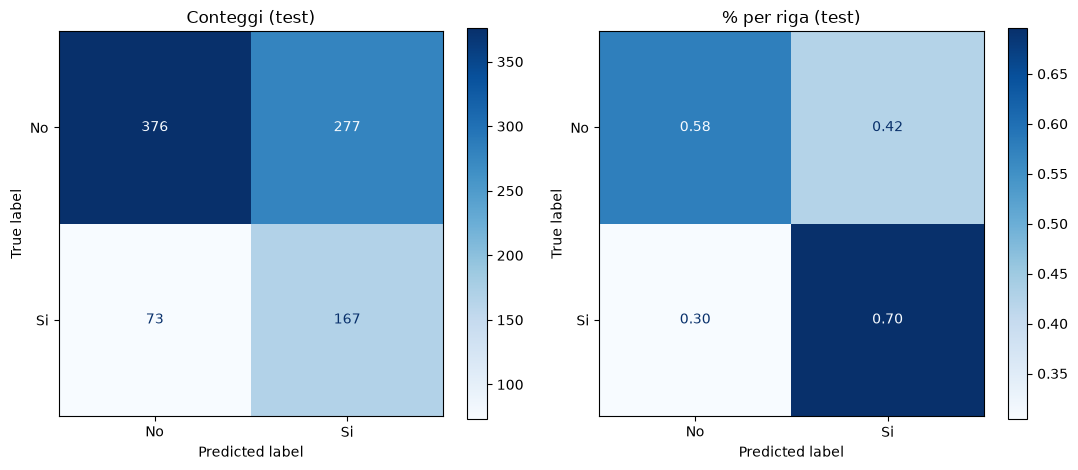

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
skl_metr.ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["No", "Si"],
                                                 cmap="Blues", values_format="d", ax=ax[0])
ax[0].set_title("Conteggi (test)")
skl_metr.ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["No", "Si"],
                                                 cmap="Blues", normalize="true", values_format=".2f", ax=ax[1])
ax[1].set_title("% per riga (test)")
plt.tight_layout()
plt.show()


#### Curva ROC

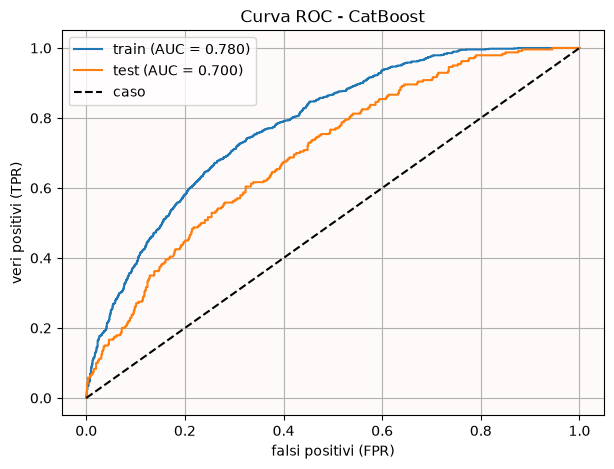

In [15]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 5))
for nome, y_vero, p in [("train", y_train, model.predict_proba(X_train)[:, 1]), ("test", y_test, model.predict_proba(X_test)[:, 1])]:
    fpr, tpr, _ = skl_metr.roc_curve(y_vero, p)
    ax.plot(fpr, tpr, label=f"{nome} (AUC = {skl_metr.roc_auc_score(y_vero, p):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="caso")
ax.set_xlabel("falsi positivi (FPR)")
ax.set_ylabel("veri positivi (TPR)")
ax.set_title("Curva ROC - CatBoost")
ax.set_facecolor("snow")
ax.legend()
ax.grid()
plt.show()

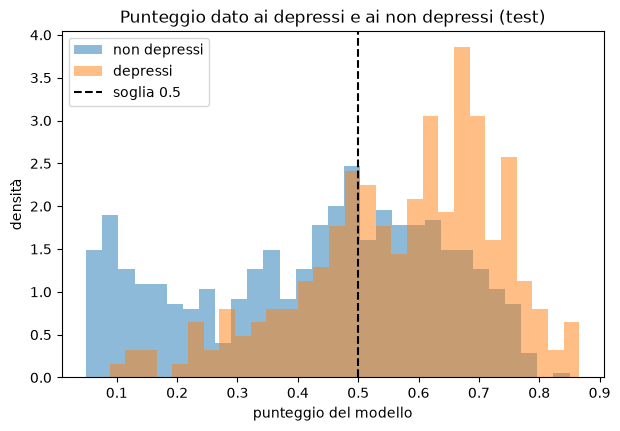

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(prob_test[(y_test == 0).values], bins=30, alpha=0.5, density=True, label="non depressi")
ax.hist(prob_test[(y_test == 1).values], bins=30, alpha=0.5, density=True, label="depressi")
ax.axvline(SOGLIA, color="k", ls="--", label=f"soglia {SOGLIA}")
ax.set_xlabel("punteggio del modello")
ax.set_ylabel("densità")
ax.set_title("Punteggio dato ai depressi e ai non depressi (test)")
ax.legend()
plt.show()
